# A Fairer Share of Park Space

How much can the distribution of park space change when its total area stays the same?
I explore this question across Chicago's 77 community areas, using public park
property boundaries dated November 2016 and population estimates from the ACS 2023
release. The maps describe park property area per resident. The later comparisons
are allocation simulations with that fixed inventory.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "greenshare").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from greenshare.data import download_all, validate_sources, prepare_data
from greenshare.metrics import weighted_gini
from greenshare.allocation import allocate
from greenshare.analysis import compare_policies, budget_sensitivity, random_reference, save_results
from greenshare import plots

pd.options.display.float_format = "{:,.3f}".format

def show_shared_figure(figure, name):
    plots.save_figure(figure, ROOT / "report" / "figures", name)
    display(figure)
    plt.close(figure)

The following cell checks the saved download hashes. If there is no saved snapshot,
it downloads the three sources from the City of Chicago portal and reads their
metadata and row-count responses. The table shows the recorded HTTP results for
those downloads, rather than treating a working landing page as proof of data access.

In [2]:
manifest = download_all(ROOT)
download_checks = pd.DataFrame([
    {"Source file": item["filename"], "HTTP status": item["http_status"],
     "Bytes": item["bytes"], "SHA-256 prefix": item["sha256"][:16]}
    for item in manifest["files"]
])
display(download_checks)
print("Snapshot date:", manifest["downloaded_utc"][:10])
print("Total downloaded bytes:", f"{download_checks['Bytes'].sum():,}")

,Source file,HTTP status,Bytes,SHA-256 prefix
0,population_metadata.json,200,56474,cf81dbe0636c455b
1,population_count.json,200,13,52293d97d79e21d9
2,population.json,200,61060,0f8f8cc315511798
3,communities_metadata.json,200,12831,6bad23c804659a0f
4,communities_count.json,200,13,52293d97d79e21d9
5,communities.geojson,200,2072102,3468ac30bd813fa1
6,parks_metadata.json,200,66089,456226b30d37dd6a
7,parks_count.json,200,14,745e839cdb3df53d
8,parks.geojson,200,2716990,293f7717c9925cde


Snapshot date: 2026-10-28
Total downloaded bytes: 4,985,586


The sources already contain the fields needed for the analysis:
[population](https://data.cityofchicago.org/d/t68z-cikk),
[community boundaries](https://data.cityofchicago.org/d/igwz-8jzy), and
[park properties](https://data.cityofchicago.org/d/ejsh-fztr).
The following cell checks the field names, positive population counts, polygon
coordinates, unique identifiers, and a complete match between the 77 community names.

In [3]:
validation = validate_sources(ROOT / "data" / "raw")
display(pd.DataFrame({
    "Check": ["Population records", "Community boundaries", "Park polygons",
              "Matched communities", "Total population estimate"],
    "Value": [validation["population_rows"], validation["community_features"],
              validation["park_features"], validation["joined_communities"],
              validation["population_total"]],
}))

,Check,Value
0,Population records,77.000
1,Community boundaries,77.000
2,Park polygons,617.000
3,Matched communities,77.000
4,Total population estimate,"2,647,621.000"


The following cell measures areas in metres, dissolves overlapping park polygons,
and intersects them with the community boundaries. Park properties can contain
paths, buildings, and sports facilities. The area here includes those surfaces.

In [4]:
frame, geometries, quality = prepare_data(ROOT)
display(frame[["area_id", "name", "population", "park_m2", "park_per_person"]].head(8)
        .rename(columns={"area_id": "Area ID", "name": "Community", "population": "Residents",
                         "park_m2": "Park area (m²)", "park_per_person": "Park m² per resident"}))
display(pd.DataFrame({
    "Spatial check": ["Park geometries repaired", "Park area before dissolving (km²)",
                      "Park area after dissolving (km²)", "Park area within communities (km²)",
                      "Park area outside communities (km²)"],
    "Value": [quality["invalid_geometries_repaired"]["parks"],
              quality["park_raw_sum_m2"] / 1e6, quality["park_union_m2"] / 1e6,
              quality["park_clipped_union_m2"] / 1e6,
              quality["park_outside_communities_m2"] / 1e6],
}))

,Area ID,Community,Residents,Park area (m²),Park m² per resident
0,1,ROGERS PARK,"53,169.000","300,831.971",5.658
1,2,WEST RIDGE,"79,220.000","746,614.763",9.425
2,3,UPTOWN,"52,674.000","1,517,168.694",28.803
3,4,LINCOLN SQUARE,"42,180.000","439,877.703",10.429
4,5,NORTH CENTER,"35,782.000","168,663.185",4.714
5,6,LAKE VIEW,"90,652.000","817,157.861",9.014
6,7,LINCOLN PARK,"62,067.000","1,613,253.974",25.992
7,8,NEAR NORTH SIDE,"91,635.000","292,219.442",3.189


,Spatial check,Value
0,Park geometries repaired,11.000
1,Park area before dissolving (km²),36.122
2,Park area after dissolving (km²),36.121
3,Park area within communities (km²),34.155
4,Park area outside communities (km²),1.966


Each community receives a simple supply measure: $x_i = a_i/p_i$, where $a_i$ is
park area and $p_i$ is population. Every resident of a community is assigned the
same value. The following cell calculates this measure and the population-weighted
citywide mean, $\bar{x}=\sum_i a_i/\sum_i p_i$.

In [5]:
area = frame["park_m2"].to_numpy(float)
population = frame["population"].to_numpy(float)
supply = area / population
city_mean = area.sum() / population.sum()
np.testing.assert_allclose(supply, frame["park_per_person"])
display(pd.DataFrame({
    "Measure": ["Park area (km²)", "Population estimate", "Mean park m² per resident",
                "Lowest community value", "Highest community value"],
    "Value": [area.sum() / 1e6, population.sum(), city_mean, supply.min(), supply.max()],
}))

,Measure,Value
0,Park area (km²),34.155
1,Population estimate,"2,647,621.000"
2,Mean park m² per resident,12.900
3,Lowest community value,0.442
4,Highest community value,182.556


The following cell places population density beside park space per resident.
The two maps use the same community boundaries. A dark area on one map need not
be dark on the other.

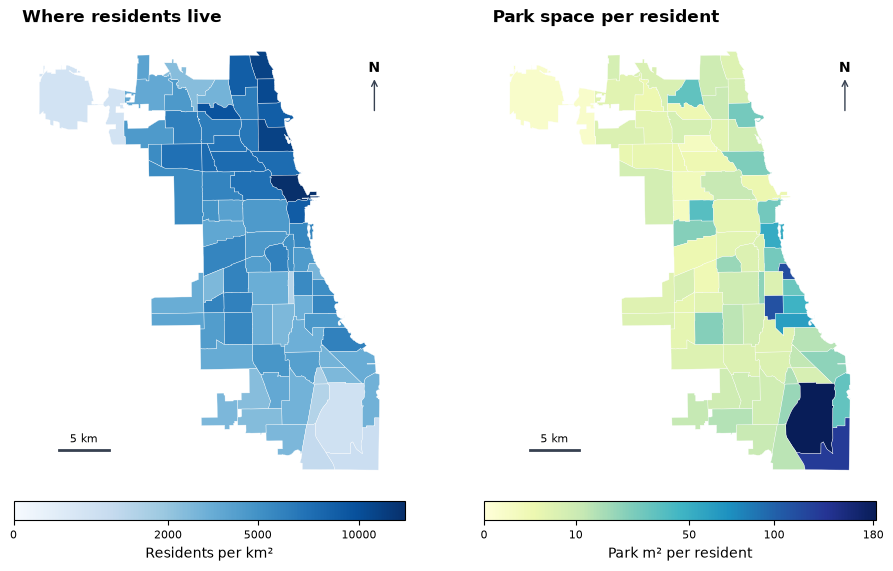

In [6]:
show_shared_figure(plots.baseline_maps(frame, geometries), "01_baseline_maps")

The Gini coefficient summarizes the gaps between community values while weighting
each community by its residents. Zero means equal supply per resident. For just 77
communities, the pairwise formula is short enough to write directly:

$$G = \frac{\sum_i\sum_j w_iw_j|x_i-x_j|}{2\bar{x}},
\qquad w_i = \frac{p_i}{\sum_j p_j}.$$

The following cell checks this direct calculation against the project's sorted formula.

In [7]:
def pairwise_gini(values, people):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(people, dtype=float)
    weights = weights / weights.sum()
    mean = np.sum(weights * values)
    if mean == 0:
        return np.nan
    gaps = np.abs(values[:, None] - values[None, :])
    return np.sum(weights[:, None] * weights[None, :] * gaps) / (2 * mean)

baseline_gini = pairwise_gini(supply, population)
np.testing.assert_allclose(baseline_gini, weighted_gini(supply, population), atol=1e-12)
print(f"Population-weighted Gini: {baseline_gini:.4f}")

Population-weighted Gini: 0.5419


The following cell shows the same distribution in two ways. The Lorenz curve sorts
residents by their community's supply and compares cumulative population with
cumulative park area. The ranked points show how far the community values spread.

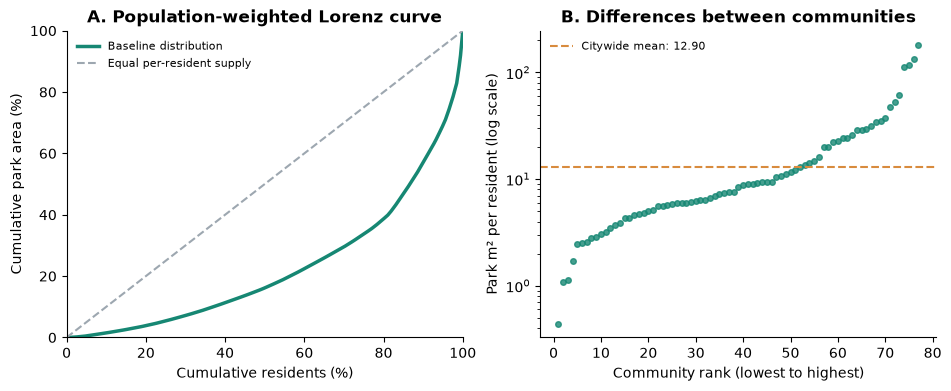

In [8]:
show_shared_figure(plots.distribution_figure(frame), "02_distribution")

## Simulation analysis

Suppose 5% of each community's park area enters a shared pool. Each community
keeps 95% of its original area, and the pool is then reassigned. Three rules divide
it equally between communities, in proportion to population, or by raising the
lowest per-resident supplies first.

The need-first rule: searches for a common
level that the available pool can support, like filling containers to the
same height, while communities above that level receive no additional area.

In [21]:
def need_first(area, people, fraction=0.05):
    retained = (1 - fraction) * area
    pool = fraction * area.sum()
    if pool == 0:
        return area.copy()
    low = np.min(retained / people)
    high = area.sum() / people.sum()
    for _ in range(80):
        level = (low + high) / 2
        required = np.maximum(0, level * people - retained).sum()
        if required < pool:
            low = level
        else:
            high = level
    awards = np.maximum(0, (low + high) / 2 * people - retained)
    awards *= pool / awards.sum()
    return retained + awards

BUDGET = 0.05
inline_allocation = need_first(area, population, BUDGET)
np.testing.assert_allclose(inline_allocation,
                           allocate(area, population, BUDGET, "need_first"), atol=1e-8)
print(f"Shared pool: {BUDGET * area.sum() / 1e6:.3f} km²")
print("The inline and project allocation functions agree.")

Shared pool: 1.708 km²
The inline and project allocation functions agree.


Compare the three rules with the original distribution by Gini coefficient, the lowest community supply, and the population
shares assigned higher or lower supply than before.

In [22]:
comparison, allocations = compare_policies(frame, budget=BUDGET)
np.testing.assert_allclose(allocations["need_first"], inline_allocation)
comparison_table = comparison[["label", "gini", "mean", "minimum",
                               "population_gaining_share", "population_losing_share"]].copy()
comparison_table[["population_gaining_share", "population_losing_share"]] *= 100
display(comparison_table.rename(columns={
    "label": "Allocation rule", "gini": "Gini", "mean": "Mean m² per resident",
    "minimum": "Minimum m² per resident", "population_gaining_share": "Residents gaining (%)",
    "population_losing_share": "Residents losing (%)",
}))

,Allocation rule,Gini,Mean m² per resident,Minimum m² per resident,Residents gaining (%),Residents losing (%)
0,Baseline,0.542,12.900,0.442,0.000,0.000
1,Equal community,0.521,12.900,1.631,66.805,33.195
2,Population share,0.515,12.900,1.065,77.189,22.811
3,Need first,0.476,12.900,5.039,31.532,68.468


Overall inequality and the lowest supply by side.


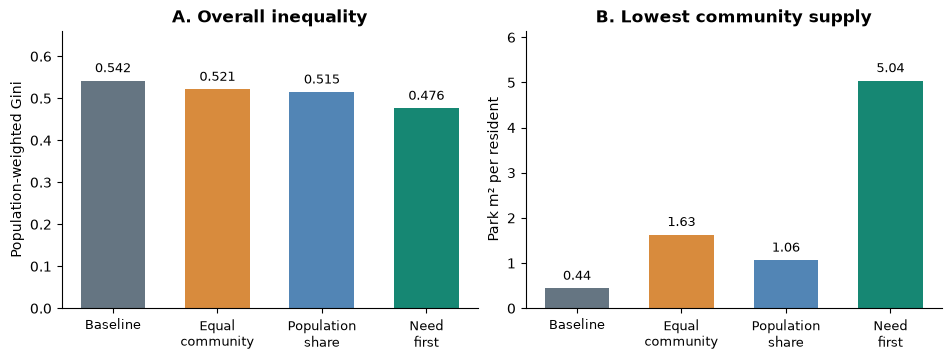

In [23]:
show_shared_figure(plots.policy_figure(comparison), "03_policy_comparison")

Individual communities under the need-first rule.
The largest gains identify where the rule directs the shared pool. 

In [24]:
changes = frame[["name", "population"]].copy()
changes["Before (m² per resident)"] = supply
changes["After (m² per resident)"] = allocations["need_first"] / population
changes["Change (m² per resident)"] = changes["After (m² per resident)"] - supply
display(changes.nlargest(5, "Change (m² per resident)")
        .rename(columns={"name": "Community", "population": "Residents"}))
display(changes.nsmallest(5, "Change (m² per resident)")
        .rename(columns={"name": "Community", "population": "Residents"}))

,Community,Residents,Before (m² per resident),After (m² per resident),Change (m² per resident)
75,OHARE,"16,281.000",0.442,5.039,4.597
20,AVONDALE,"36,350.000",1.075,5.039,3.963
25,WEST GARFIELD PARK,"16,345.000",1.136,5.039,3.903
22,HUMBOLDT PARK,"55,015.000",1.690,5.039,3.349
57,BRIGHTON PARK,"42,360.000",2.478,5.039,2.560


,Community,Residents,Before (m² per resident),After (m² per resident),Change (m² per resident)
50,SOUTH DEERING,"15,100.000",182.556,173.428,-9.128
54,HEGEWISCH,"8,895.000",132.702,126.067,-6.635
35,OAKLAND,"4,373.000",117.497,111.623,-5.875
39,WASHINGTON PARK,"12,362.000",113.299,107.634,-5.665
41,WOODLAWN,"24,437.000",61.236,58.174,-3.062


Five largest gains and losses (community averages).


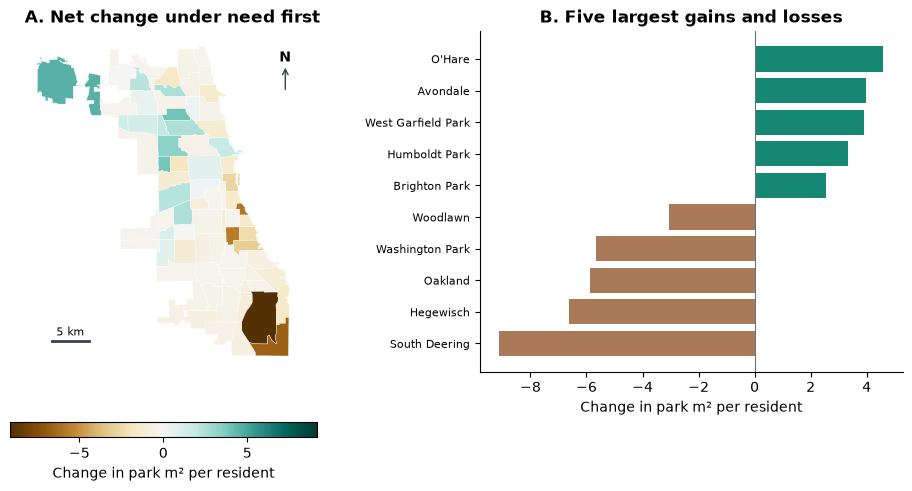

In [25]:
show_shared_figure(plots.change_figure(frame, geometries, allocations), "04_net_changes")

Because total park area and population stay fixed, every rule has the same mean
$\bar{x}$. A better distribution can therefore raise the lowest values while leaving
that mean unchanged. The following cell checks this identity and counts residents
in communities with gains and losses.

In [26]:
for method, final_area in allocations.items():
    np.testing.assert_allclose(final_area.sum(), area.sum(), rtol=1e-12)
    np.testing.assert_allclose(final_area.sum() / population.sum(), city_mean, rtol=1e-12)
need = comparison.set_index("method").loc["need_first"]
display(Markdown(
    f"The mean remains **{city_mean:.2f} m² per resident**. Under need first, "
    f"communities containing **{need.population_gaining_share:.1%}** of residents gain supply, "
    f"and communities containing **{need.population_losing_share:.1%}** lose supply."
))

The mean remains **12.90 m² per resident**. Under need first, communities containing **31.5%** of residents gain supply, and communities containing **68.5%** lose supply.

The 5% pool is one choice. Next,  repeat all three rules over 21 pool
sizes between 0% and 20%, with fixed original area and population data.

In [27]:
sensitivity = budget_sensitivity(frame, budgets=np.linspace(0, 0.20, 21))
selected_budgets = sensitivity[np.isclose(sensitivity["budget"], 0.05)
                               | np.isclose(sensitivity["budget"], 0.10)
                               | np.isclose(sensitivity["budget"], 0.20)]
display(selected_budgets[["budget", "label", "gini", "minimum"]].rename(columns={
    "budget": "Pool fraction", "label": "Allocation rule", "gini": "Gini",
    "minimum": "Minimum m² per resident",
}))

,Pool fraction,Allocation rule,Gini,Minimum m² per resident
15,0.050,Equal community,0.521,1.631
16,0.050,Population share,0.515,1.065
17,0.050,Need first,0.476,5.039
30,0.100,Equal community,0.502,2.188
31,0.100,Population share,0.488,1.687
32,0.100,Need first,0.422,6.332
60,0.200,Equal community,0.467,2.964
61,0.200,Population share,0.433,2.933
62,0.200,Need first,0.331,8.042


Use dotted line to mark the 5% comparison used above.

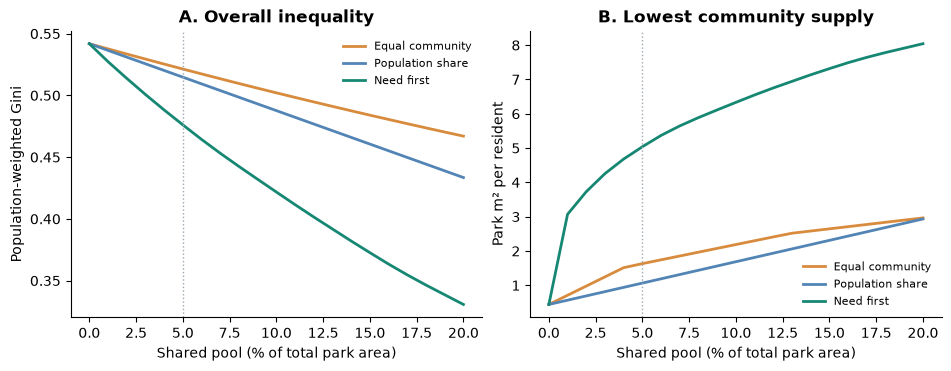

In [28]:
show_shared_figure(plots.sensitivity_figure(sensitivity), "05_budget_sensitivity")

For another point of comparison, the following cell divides the 5% pool using 200
random share vectors. A Dirichlet distribution with all parameters equal to one
treats communities symmetrically when drawing those shares. The spread describes
these random allocation choices.

In [29]:
random = random_reference(frame, budget=BUDGET, repeats=200, seed=2026)
display(random[["gini", "minimum"]].agg(["min", "median", "max"]).rename(columns={
    "gini": "Gini", "minimum": "Minimum m² per resident",
}))
print(f"Random allocations compared: {len(random)}")

,Gini,Minimum m² per resident
min,0.514,0.421
median,0.523,1.113
max,0.530,2.315


Random allocations compared: 200


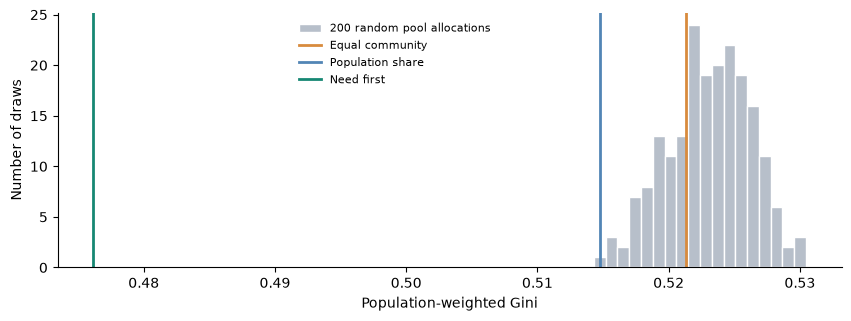

In [ ]:
show_shared_figure(plots.random_figure(random, comparison), "06_random_reference")
info = save_results(ROOT, frame, quality, comparison, allocations, sensitivity, random)


In [32]:
display(Markdown(
    f"Across **{len(frame)} communities**, the baseline Gini is **{baseline_gini:.3f}**. "
    f"With a **{BUDGET:.0%} shared pool**, need first gives a Gini of **{need.gini:.3f}**, "
    f"a **{1 - need.gini / baseline_gini:.1%}** reduction. The lowest community supply "
    f"changes from **{supply.min():.2f}** to **{need.minimum:.2f} m² per resident**. "
    f"The citywide mean stays at **{city_mean:.2f} m² per resident**. "
    "These results show how an explicit allocation rule can change distribution "
    "without increasing the total area."
))

Across **77 communities**, the baseline Gini is **0.542**. With a **5% shared pool**, need first gives a Gini of **0.476**, a **12.1%** reduction. The lowest community supply changes from **0.44** to **5.04 m² per resident**. The citywide mean stays at **12.90 m² per resident**. These results show how an explicit allocation rule can change distribution without increasing the total area.